# 02 · Connectivity: projections & connection lists

Notebooks [00 · Welcome to py-spinnaker2](./00_welcome.ipynb) and [01 · Core concepts](./01_core_concepts.ipynb) built populations and
parametrized their neurons. This notebook is about the **wiring** — the [`Projection`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Projection),
which carries spikes from one population to another through synapses.

**By the end of this notebook you will be able to:**

- write connection lists and know exactly what `weight` and `delay` mean (and their limits),
- build the common wiring patterns (one-to-one, all-to-all, random) as connection lists,
- turn a dense weight matrix into a projection, and combine multiple projections.

> **Info**
>
> Runs on Brian2 by default — flip `USE_HARDWARE` to run on a board.

In [1]:
from spinnaker2 import snn, helpers, brian2_sim
import numpy as np
import matplotlib.pyplot as plt

USE_HARDWARE = True

if USE_HARDWARE:
    from spinnaker2 import hardware

    hw = hardware.SpiNNcloud48NodeBoard()  # or hardware.SpiNNaker2Chip()
else:
    hw = brian2_sim.Brian2Backend()

print("Running on backend:", type(hw).__name__)

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


Running on backend: SpiNNcloud48NodeBoard


## 1. A projection is a list of synapses

A `Projection` connects a **pre** population to a **post** population. You describe it as a
**connection list** — a list of 4-element entries:

```python
[pre_index, post_index, weight, delay]
```

```python
proj = snn.Projection(pre=source, post=target, connections=conns)
```

- **`pre_index` / `post_index`** — neuron indices *local* to each population.
- **`weight`** — synaptic strength.
- **`delay`** — how many extra steps the post core waits before processing the spike (not
  travel time — see Section 2).

py-spinnaker2 wires populations with **explicit connection lists**. Each common pattern is a
one-line comprehension (shown below), and you can also generate the list directly from a weight
matrix (last section).

> **Info**
>
> PyNN-style connector classes (`OneToOne`, `FixedProbability`, …) are planned for a future release.

## 2. Weights and delays, precisely

**Weight**
- It's a **signed integer**. **Positive = excitatory** (pushes the post neuron toward firing),
  **negative = inhibitory**.
- The number of bits — and therefore the range — depends on the **post population's neuron
  model**. For [`lif`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-lif) it's 5 bits → `[-15, 15]`; `lif_no_delay` gives 8 bits → `[-127, 127]`;
  the `_32bit` variants give 20 bits. (See [01 · Core concepts](./01_core_concepts.ipynb) for how to check a model's weight precision.)
- Values outside the range are **clipped**, and non-integers are **rounded toward zero**, when
  the network is mapped to hardware. So `2.7 → 2`, `20 → 15` (on `lif`), `-30 → -15`.

**Delay**
- Also model-dependent: `lif` allows `0–7` (3 bits); the `_no_delay` models force `0`.
- The spike itself isn't slowed down in transit — it arrives promptly, with one base step for
  that hop. `delay` instead tells the *receiving* core to wait before acting on it: the spike
  sits in a buffer for `delay` extra steps before it's added to the neuron's input. That's why
  the **effective delay is `delay + 1`**: one step to arrive, plus however many steps it then
  waits. A spike with `delay=0` is processed on the *next* time step. (See
  [06 · Hardware architecture](./06_hardware_architecture.ipynb) for more on cores.)

#### Demo: a delay line

We create a single input neuron (stimulus) that spikes once at time step 5. We then connect it
to **8 LIF neurons**, giving each connection a different delay `0, 1, …, 7` (and a weight big
enough to make the target fire on arrival). Neuron `i` should therefore fire at
`5 + delay + 1` (`delay` = `i` in this case). This creates a diagonal pattern over time in the
plot below.

In [2]:
stim = snn.Population(size=1, neuron_model="spike_list", params={0: [5]}, name="stim")

post = snn.Population(
    size=8,
    neuron_model="lif",
    params={"threshold": 1.0, "alpha_decay": 0.9, "reset": "reset_by_subtraction"},
    name="lif_pop",
    record=["spikes"],
)

# input neuron 0 -> post neuron i, weight 2 (enough to fire), delay i
conns = [[0, i, 2, i] for i in range(8)]

net = snn.Network("delay_line")
net.add(stim, post, snn.Projection(pre=stim, post=post, connections=conns))

timesteps = 20
hw.run(net, timesteps)
print("post spike times:", post.get_spikes())

Number of cores needed: 2
Number of available cores: 7104
Sim duration: 0.03 s


Recording post-processing duration: 0 s
post spike times: {0: [6], 1: [7], 2: [8], 3: [9], 4: [10], 5: [11], 6: [12], 7: [13]}


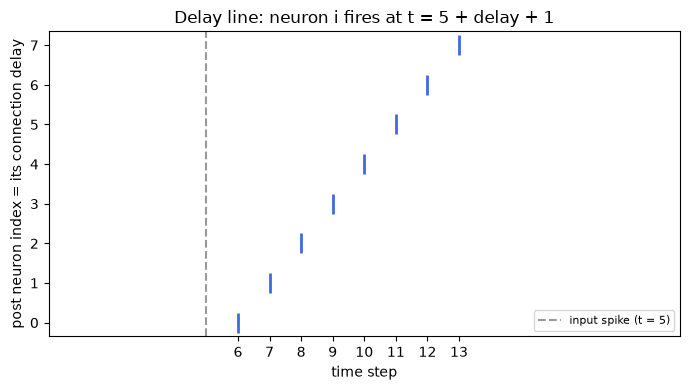

In [3]:
idx, timestep = helpers.spike_times_dict_to_arrays(post.get_spikes())

plt.figure(figsize=(7, 4))
plt.plot(timestep, idx, "|", ms=14, mew=2, color="royalblue")
plt.axvline(5, ls="--", c="0.6", label="input spike (t = 5)")
plt.xlabel("time step")
plt.xticks(timestep)  # tick at each time a neuron fired
plt.ylabel("post neuron index = its connection delay")
plt.title("Delay line: neuron i fires at t = 5 + delay + 1")
plt.xlim(0, timesteps)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

Each neuron fires exactly one step later than the previous one, and the *first* one
(`delay = 0`) fires at `t = 6`, not `t = 5` — that's the `+1`. Keep the `delay + 1` rule in
mind whenever timing matters.

## 3. Building connection patterns

Because connections are plain lists, the standard wiring patterns are one-line comprehensions.
Here are the three you'll reach for most (as noted in Section 1, py-spinnaker2 doesn't ship these
as built-in connector classes yet — that's the planned PyNN-style API — so for now they're just
plain functions you can copy or adapt):

In [4]:
# one-to-one: neuron i (pre) -> neuron i (post)
def one_to_one(n, w, d=0):
    return [[i, i, w, d] for i in range(n)]


# all-to-all: every pre neuron -> every post neuron
def all_to_all(n_pre, n_post, w, d=0):
    return [[i, j, w, d] for i in range(n_pre) for j in range(n_post)]


# fixed-probability: each possible pre->post connection exists with probability p
def fixed_prob(n_pre, n_post, p, w, d=0, rng=None):
    rng = rng or np.random.default_rng()
    return [[i, j, w, d] for i in range(n_pre) for j in range(n_post) if rng.random() < p]


# fixed fan-in: each post neuron receives from k randomly chosen pre neurons
# (this is the pattern the synfire chain in notebook 00 used)
def fixed_fan_in(n_pre, n_post, k, w, d=0, rng=None):
    rng = rng or np.random.default_rng()
    return [[int(i), j, w, d] for j in range(n_post) for i in rng.permutation(n_pre)[:k]]

The clearest way to *see* a connection list is as a **weight matrix**: rows = pre neurons,
columns = post neurons, each cell the weight. A `Projection` stores exactly that (as a sparse
matrix), so we can plot `proj.sparse_weights` for each pattern:

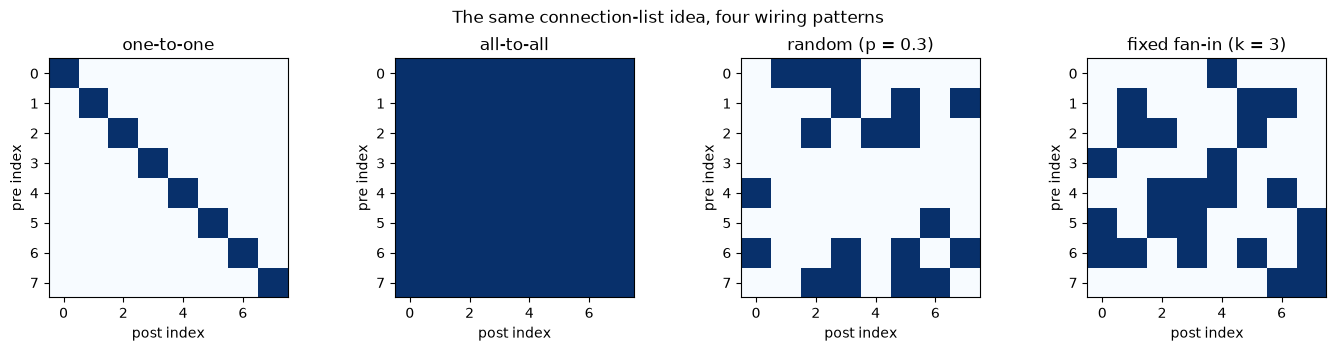

In [5]:
pre = snn.Population(size=8, neuron_model="lif", params={}, name="pre")
post = snn.Population(size=8, neuron_model="lif", params={}, name="post")

rng = np.random.default_rng(0)
patterns = {
    "one-to-one": snn.Projection(pre=pre, post=post, connections=one_to_one(8, 5)),
    "all-to-all": snn.Projection(pre=pre, post=post, connections=all_to_all(8, 8, 5)),
    "random (p = 0.3)": snn.Projection(pre=pre, post=post, connections=fixed_prob(8, 8, 0.3, 5, rng=rng)),
    "fixed fan-in (k = 3)": snn.Projection(pre=pre, post=post, connections=fixed_fan_in(8, 8, 3, 5, rng=rng)),
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (title, proj) in zip(axes, patterns.items()):
    ax.imshow(proj.sparse_weights.toarray(), cmap="Blues", vmin=0, vmax=5)
    ax.set_title(title)
    ax.set_xlabel("post index")
    ax.set_ylabel("pre index")
fig.suptitle("The same connection-list idea, four wiring patterns")
plt.tight_layout()
plt.show()

## 4. The reverse: a weight matrix → connection list

The plots above turned connection lists *into* weight matrices. Often you already have the
matrix you computed or trained — and want to go the other
way. `connection_list_from_dense_weights` does exactly that: give it a 2-D array (rows = pre,
columns = post) and it returns a list of connection entries (`[pre, post, weight, delay]`), one
per matrix cell.

In [6]:
from spinnaker2 import ann2snn_helpers

# Weight matrix for 2 pre neurons (rows) -> 3 post neurons (columns).
# W[i, j] is the weight from pre i to post j;  0 means "no synapse".
W = np.array(
    [
        [2, 0, -3],
        [0, 4, 0],
    ]
)

conns = ann2snn_helpers.connection_list_from_dense_weights(W, delay=1)
print(conns)

[[0, 0, np.int64(2), 1], [0, 1, np.int64(0), 1], [0, 2, np.int64(-3), 1], [1, 0, np.int64(0), 1], [1, 1, np.int64(4), 1], [1, 2, np.int64(0), 1]]


It writes an entry for *every* cell, including the zero-weight ones, so the result is dense.
That matters on hardware: each entry becomes a real synapse-row entry with its own target,
weight, and delay bits, and gets processed every relevant time step whether the weight is zero
or not — a zero-weight synapse costs the same memory and compute as any other, it just
contributes nothing to the neuron. For a sparse matrix, filter out the zero cells yourself
before building the connection list.

## 5. Combining projections

Two more things worth knowing:

- **Multiple projections into the same population add up.** You can give a population several
  incoming projections (e.g. one excitatory, one inhibitory, from different sources); their
  synaptic effects are summed at the post neuron. This is how the synfire chain in [00 · Welcome to py-spinnaker2](./00_welcome.ipynb)
  layered feed-forward excitation and local inhibition.
- **A population can connect to itself** (recurrent connections) — just use the same population
  as both `pre` and `post`. The synfire chain's within-group inhibition was exactly this:
  `snn.Projection(pre=pop, post=pop, …)`.

## Recap & what's next

You now know how to:

- write connection lists `[pre, post, weight, delay]`, with integer weights (sign = exc/inh,
  range set by the post model) and the **`delay + 1`** effective-delay rule,
- build **one-to-one / all-to-all / random** patterns as comprehensions and visualise them as
  weight matrices,
- generate a projection from a dense weight matrix, and combine multiple / recurrent
  projections.

**Next up — [03 · LIF Conv2D](./03_lif_conv2d.ipynb):** a projection you *don't* enumerate —
a shared filter swept across an image, and the feature maps it produces.